# 05 - Intraday extension: realized variance from 15-minute bars

## Why intraday data
Notebook 02 measured volatility as the std of 5 *daily* returns: one number built from 5 noisy observations, overlapping with the neighbouring day's target.
With **high-frequency data** we can do better. If we observe the price every 15 minutes, the sum of squared intraday log returns converges to the true
variance of the day as the sampling gets finer (Andersen & Bollerslev 1998; Barndorff-Nielsen & Shephard 2002):
$$RV_t=\sum_{i=1}^{n} r_{t,i}^2 \;\xrightarrow{\;n\to\infty\;}\; \int_{t-1}^{t}\sigma_s^2\,ds .$$
This is called **realized variance** (RV): a *measurement* of the day's variance rather than a rough guess, far less noisy than $|r_t|$ or a 5-day std.
Overnight returns are excluded (we measure what happens during the 09:30-16:00 New York session).

**Microstructure noise.** At very fine sampling (seconds), bid-ask bounce and discreteness bias RV upward; 5-15 minute bars are the usual compromise.
We use **15-minute** bars because the free IEX feed (about 2-3% of US volume) is thin for some ETFs (XLE, XLF, GLD), and thin 5-minute bars would be mostly empty.

## What changes versus the daily analysis
| | daily version (notebooks 01-04) | intraday version (this notebook) |
|---|---|---|
| Target | $\ln$ of std of last 5 daily returns (overlapping windows) | $\ln RV_t$, **one day, non-overlapping** |
| Baseline | HAR on RV5, RV22, $\ln\lvert r\rvert$ | **HAR-RV** (Corsi 2009): day, 5-day mean, 22-day mean of past RV |
| Sample | 2016-2026, 1950 test days | **2020-07-27 -> 2026-10**, ~800 test days (Alpaca IEX history starts mid-2020) |
| Extra control | none | **weekday dummies** (see below) |

Because the target changed (daily, not smoothed) the baseline $R^2$ is **lower (0.3-0.4)**: it is *not* comparable with the 0.73-0.78 of the smooth 5-day target.

In [1]:
import os, sys, warnings
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import model_pipeline as mp, intraday as it
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": .3})
START, END = "2016-01-01", "2026-10-31"
# bars are cached in data/ (not committed); re-downloading needs ALPACA_KEY / ALPACA_SECRET

## 1. Daily RV from intraday bars vs the 5-day std of daily returns (SPY)

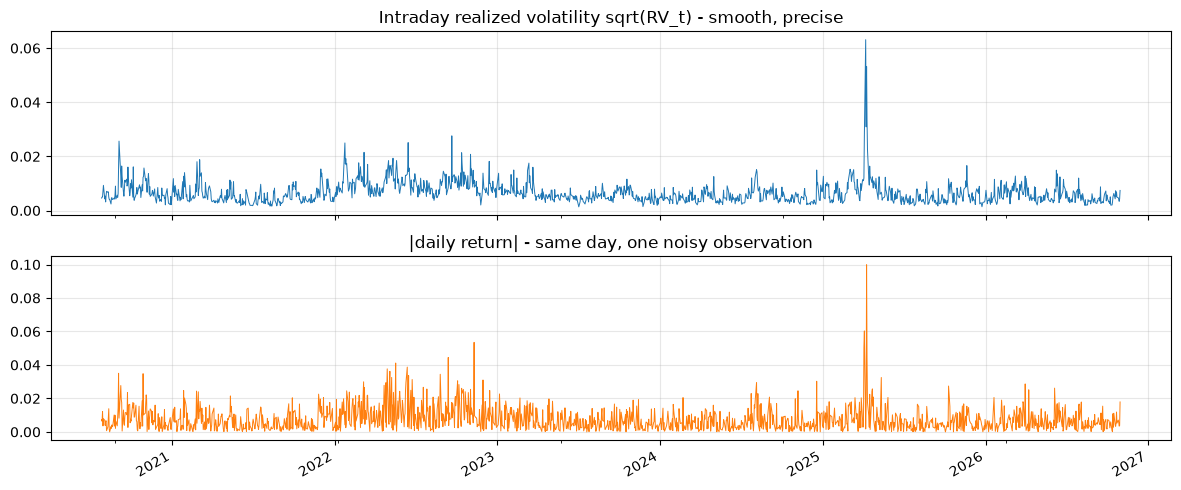

corr(sqrt RV, |r|) = 0.439  bars used: 46691  days: 1573


In [2]:
close = it.fetch_bars("SPY", START, END)
rv = it.daily_rv(close)
px = mp.fetch_prices("SPY", START, END)
rd = np.log(px).diff()
cmp_ = pd.DataFrame({"intraday RV (sqrt, daily vol)": np.sqrt(rv), "|daily return|": rd.abs()}).dropna()
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
cmp_.iloc[:, 0].plot(ax=ax[0], lw=.7, title="Intraday realized volatility sqrt(RV_t) - smooth, precise")
cmp_.iloc[:, 1].plot(ax=ax[1], lw=.7, color="tab:orange", title="|daily return| - same day, one noisy observation")
plt.tight_layout(); plt.show()
print("corr(sqrt RV, |r|) =", round(cmp_.corr().iloc[0, 1], 3), " bars used:", len(close), " days:", len(rv))

Both measure the same thing, but a single daily return is a very noisy estimate of that day's volatility (a large move can happen on a calm day by chance).
The intraday measure uses ~25 observations per day and is much smoother.

## 2. A trap: weekday seasonality

Both Wikipedia traffic and volatility have **day-of-week patterns** (Wikipedia: fewer visits at weekends, so the log-change of views *Monday vs the previous trading day* is
systematically different from Tuesday's; volatility: Monday/Friday tend to differ from mid-week). A model with a "views change" feature can then "predict"
volatility just by *knowing the weekday*, with no information about attention. Such a gain is spurious.

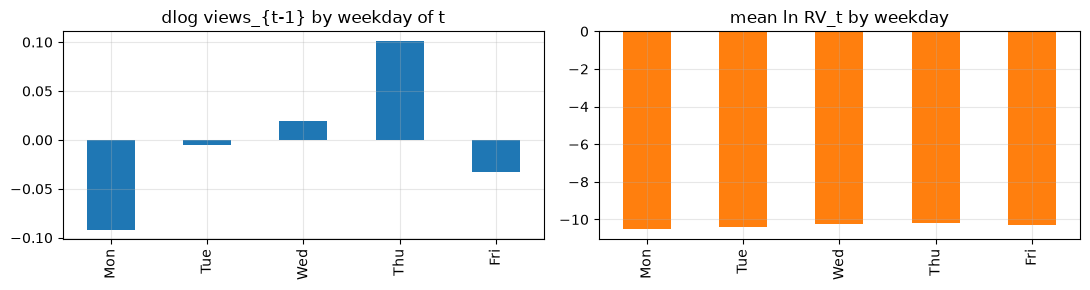

In [3]:
X, y = it.build_intraday("SPY", "Federal_Reserve", START, END)
wk = pd.DataFrame({"mean dlog views": X["views_l1"].groupby(X.index.dayofweek).mean(),
                   "mean ln RV": y.groupby(y.index.dayofweek).mean()})
wk.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
wk.iloc[:, 0].plot.bar(ax=ax[0], title="dlog views_{t-1} by weekday of t")
wk.iloc[:, 1].plot.bar(ax=ax[1], color="tab:orange", title="mean ln RV_t by weekday")
plt.tight_layout(); plt.show()

The weekday pattern is visible. The fix is simple: add weekday dummies to **both** models (baseline and attention), so any improvement from attention must come
on top of the calendar effect. We report results **with and without** the control.

## 3. Results

In [4]:
df = pd.read_csv("results/intraday_results.csv")
ols = df[df.model == "ols"]
ols[["ticker", "page", "dow", "n_oos", "r2_oos_baseline", "r2_oos_gain", "p_dm", "p_cw", "p_cw_holm"]].round(4)

,ticker,page,dow,n_oos,r2_oos_baseline,r2_oos_gain,p_dm,p_cw,p_cw_holm
0,QQQ,Nvidia,False,801,0.3397,0.0061,0.0649,0.0018,0.0110
1,QQQ,Nvidia,True,801,0.3556,0.0026,0.2032,0.0248,0.1488
4,SPY,Federal_Reserve,False,801,0.3806,-0.0006,0.5248,0.0974,0.2439
5,SPY,Federal_Reserve,True,801,0.4003,-0.0034,0.7192,0.3707,1.0000
8,XLE,Petroleum,False,801,0.2880,0.0053,0.1958,0.0026,0.0128
9,XLE,Petroleum,True,801,0.2870,0.0019,0.3318,0.0285,0.1488
12,XLF,JPMorgan_Chase,False,801,0.3618,0.0021,0.3300,0.0813,0.2439
13,XLF,JPMorgan_Chase,True,801,0.3703,-0.0023,0.7389,0.4734,1.0000
16,XLK,Apple_Inc.,False,801,0.3825,0.0072,0.1278,0.0143,0.0572
17,XLK,Apple_Inc.,True,801,0.3965,0.0033,0.2736,0.0654,0.2616


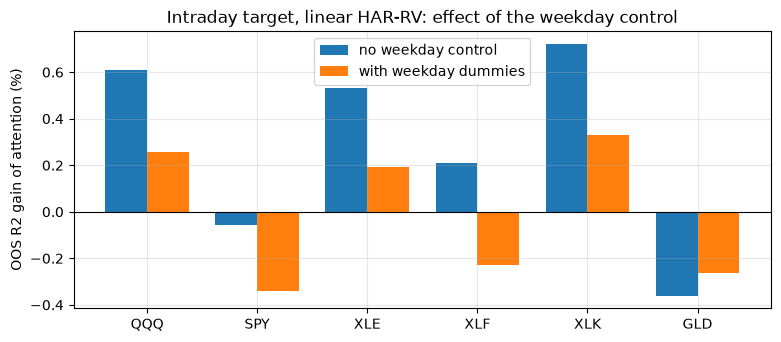

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
w = .38; x = np.arange(6)
a = ols[~ols.dow].set_index("ticker"); b = ols[ols.dow].set_index("ticker")
ax.bar(x - w/2, 100*a.r2_oos_gain, w, label="no weekday control"); ax.bar(x + w/2, 100*b.r2_oos_gain, w, label="with weekday dummies")
ax.set_xticks(x); ax.set_xticklabels(a.index); ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("OOS R2 gain of attention (%)"); ax.legend(); ax.set_title("Intraday target, linear HAR-RV: effect of the weekday control"); plt.show()

**Reading.**
- **Without** weekday control, Clark-West + Holm suggests QQQ/Nvidia (adj. $p\approx0.011$) and XLE/Petroleum ($p\approx0.013$) are significant: this would look like a discovery.
- **With** weekday dummies the gains shrink by more than half (e.g. QQQ 0.61% -> 0.26%) and **no pair survives Holm** (best adjusted $p=0.149$).
  Part of the apparent signal was a calendar artifact.
- What remains is a small, consistently positive but not significant hint for tech-related pairs (QQQ/Nvidia, XLK/Apple; raw Clark-West $p\approx0.02-0.07$).
  With ~800 test days and gains of a few tenths of a percent, the test has little power: *absence of evidence, not evidence of absence*.

## 4. Gradient boosting on the intraday target

In [6]:
gb = df[df.model == "gbm"]
gb[["ticker", "dow", "n_oos", "r2_oos_baseline", "r2_oos_gain", "p_dm", "p_dm_holm"]].round(4)

,ticker,dow,n_oos,r2_oos_baseline,r2_oos_gain,p_dm,p_dm_holm
2,QQQ,False,763,0.3048,0.0103,0.2324,1.0
3,QQQ,True,763,0.3137,-0.0032,0.5986,1.0
6,SPY,False,763,0.3361,-0.0071,0.6932,1.0
7,SPY,True,763,0.3453,-0.0138,0.8419,1.0
10,XLE,False,763,0.2780,-0.0126,0.7818,1.0
11,XLE,True,763,0.2738,-0.0058,0.6732,1.0
14,XLF,False,763,0.3235,-0.0136,0.7933,1.0
15,XLF,True,763,0.3313,-0.0163,0.8448,1.0
18,XLK,False,763,0.3408,0.0107,0.2109,1.0
19,XLK,True,763,0.3516,0.0085,0.2312,1.0


Trees do not find a significant gain either (Diebold-Mariano with Holm; Clark-West is blank on purpose, it is not valid for trees). Their Clark-West p-values would look
"significant" even when the MSE gets worse, a good reminder of why test choice matters.

## Conclusions and caveats
1. A cleaner target (intraday RV, one-day horizon) lets small effects show up, but after controlling for the weekday the **evidence is still not significant**.
2. The weekday trap is a general lesson: **feature engineering that mixes calendars (weekend traffic vs trading days) can create fake predictability.**
3. Caveats: IEX is 2-3% of volume (RV from thin bars is noisier than from consolidated tape); history only from mid-2020 (800 test days: low power);
   15-minute sampling; six hand-picked pairs; the daily and intraday pipelines are not directly comparable in $R^2$.
4. Next steps with real value: consolidated-tape 1-5 minute data (paid), a pooled panel across many pairs, event-window designs around earnings.